In [1]:
import xarray as xr

ds = xr.open_dataset("/Users/heeowen/Projects/hydrogeopulse/data/GRCTellus.JPL.200204_202609.GLO.RL06.3M.MSCNv04.nc")
ds

<xarray.Dataset> Size: 2GB
Dimensions:        (time: 261, lat: 360, lon: 720, bounds: 2)
Coordinates:
  * time           (time) datetime64[ns] 2kB 2002-04-17T12:00:00 ... 2026-09-16
  * lat            (lat) float64 3kB -89.75 -89.25 -88.75 ... 88.75 89.25 89.75
  * lon            (lon) float64 6kB 0.25 0.75 1.25 1.75 ... 358.8 359.2 359.8
Dimensions without coordinates: bounds
Data variables:
    lwe_thickness  (time, lat, lon) float64 541MB ...
    uncertainty    (time, lat, lon) float64 541MB ...
    lat_bounds     (lat, bounds) float64 6kB ...
    lon_bounds     (lon, bounds) float64 12kB ...
    time_bounds    (time, bounds) datetime64[ns] 4kB ...
    mascon_ID      (lat, lon) float64 2MB ...
    GAD            (time, lat, lon) float64 541MB ...
Attributes: (12/51)
    Conventions:                CF-1.6, ACDD-1.3, ISO 8601
    Metadata_Conventions:       Unidata Dataset Discovery v1.0
    standard_name_vocabulary:   NetCDF Climate and Forecast (CF) Metadata Con...
    title:                      JPL GRACE and GRACE-FO MASCON RL06.3Mv04
    summary:                    Monthly gravity solutions from GRACE and GRAC...
    keywords:                   Solid Earth, Geodetics/Gravity, Gravity, liqu...
    ...                         ...
    C_20_substitution:          TN-14; Loomis et al., 2019, Geophys. Res. Let...
    C_30_substitution:          TN-14; Loomis et al., 2019, Geophys. Res. Let...
    user_note_1:                The accelerometer on the GRACE-B spacecraft w...
    user_note_2:                The accelerometer on the GRACE-D spacecraft b...
    journal_reference:          Watkins, M. M., D. N. Wiese, D.-N. Yuan, C. B...
    date_created:               2026-11-10T07:11:47Z

In [2]:
print ("Variable:", ds.lwe_thickness.dims, ds.lwe_thickness.units)
print ("Start:", ds.time.values.min())
print ("End:", ds.time.values.max())
print ("Count:", ds.time.size, "months")

Variable: ('time', 'lat', 'lon') cm
Start: 2002-04-17T12:00:00.000000000
End: 2026-09-16T00:00:00.000000000
Count: 261 months


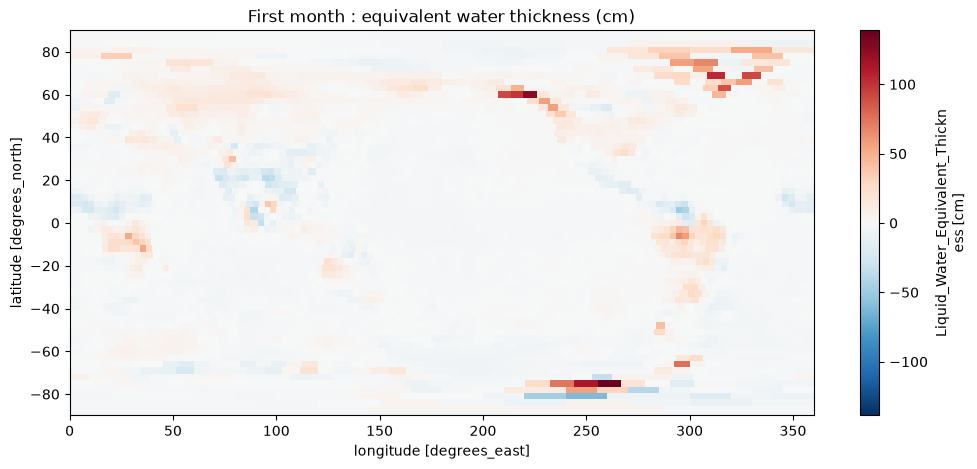

In [3]:
import matplotlib.pyplot as plt
ds.lwe_thickness.isel(time=0).plot(figsize=(12,5))
plt.title("First month : equivalent water thickness (cm)")
plt.show()

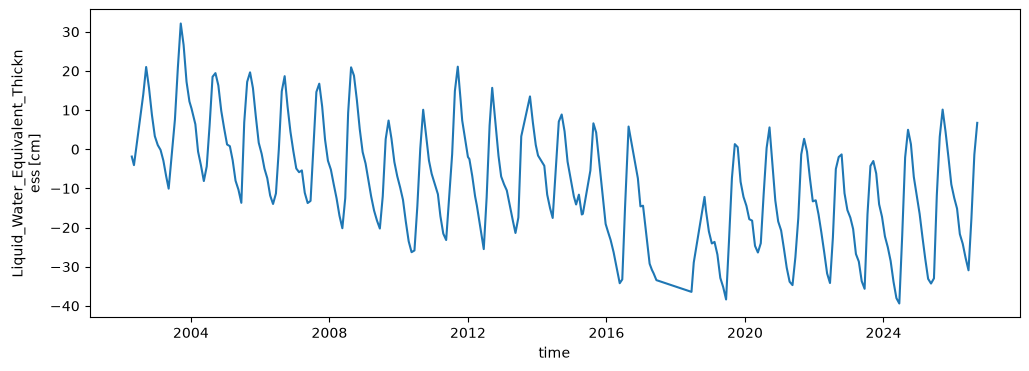

In [4]:
import numpy as np

da = ds.lwe_thickness       # (time, lat, lon), cm

# 1. define a basin box , lon in (0-360)
#North India / Ganges (big, strong depletion signal)
lat_min, lat_max = 22,30
lon_min, lon_max = 74,88

box = da.where(
    (da.lat >= lat_min) & (da.lat <= lat_max) &
    (da.lon >= lon_min) & (da.lon <= lon_max )
)

# 2. area weighted avg over the box 
weights = np.cos(np.deg2rad(da.lat))
series = box.weighted(weights).mean(dim=["lat","lon"])

# 3 viz
series.plot(figsize=(12,4))

#We should see a sawtooth, indicating the monsoon in Ganges basin

In [11]:
#Monsoon peaks around July-August, dataset will indicate water accumulation around August, as it takes time
#We know Ganges monsoon peaks around August, but we dont hardcode it, we use sine and cosine to discover it

#Caveat : Real monsoon doesn't model perfect sine graph. it has fast accumulation, slow drawdown
#So: add a 6-month wave lets the model bend asymmetrically

#Form a straight line for the trend. Where Intercept + slope . time captures the slow drift

# Fit all five together with least squares. Splits our signal into 3 labelled parts :
# 1. the sin/cos part = season
# 2. The line = trend
# 3. Leftover = residual (for anomaly detection later)

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

# xarray -> clean pandas series, drop the gap months
s = series.to_series().dropna()

# time axis in years since start. this is what handles the 2017-18 gap properly
#The 11-month data gap between July 2017 and May 2018 happened because the original GRACE satellites 
#ran out of fuel and were retired before the replacement satellites could be launched into orbit

t = (s.index - s.index[0]).days.values / 365.25
#print(t)
#t is in stamp per data point format, measured in years from the start

# build the design matrix : [intercept, trend, annual sin/cos, semiannual sin/cos]
X = np.column_stack([
    np.ones_like(t),       #interecept
    t,                     #linear trend (slope = cm per year)
    np.sin(2*np.pi*t),     #annual (period 1 yr)
    np.cos(2*np.pi*t),    
    np.sin(4*np.pi*t),     # semiannual (period 0.5 yr)
    np.cos(4*np.pi*t),
])

model = sm.OLS(s.values, X).fit()

# pull the pieces apart
seasonal = X[:, 2:6] @ model.params[2:6] #only the sin/cos contribution
deseasonalised = s.values - seasonal    #trend + residual remain
#we deseason because we want to strip out the predictable every year rhythm (where the basin filling during monsoon, and drain during dry szn)
#the swing is huge and it repeats, but that's not what we care about. 
#What we care about is : "does the basin get a little less water back each year than the year before"
residual = model.resid

print("OLS trend slope:", round(model.params[1],3), "cm/year")

OLS trend slope: -1.065 cm/year


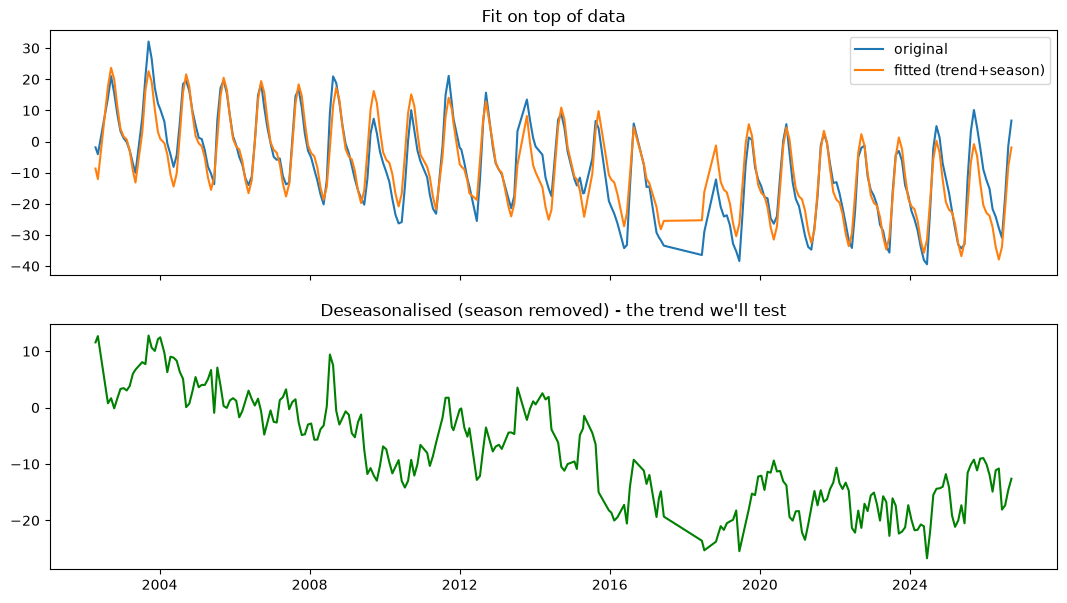

In [13]:
fig, ax = plt.subplots(2, 1, figsize=(13,7), sharex=True)
ax[0].plot(s.index, s.values, label="original")
ax[0].plot(s.index, X[:,0:2]@model.params[0:2] + seasonal, label="fitted (trend+season)")
ax[0].legend(); ax[0].set_title("Fit on top of data")
ax[1].plot(s.index, deseasonalised, color = "green")
ax[1].set_title("Deseasonalised (season removed) - the trend we'll test")
plt.show() 

#Output, top plot blue is the real data. Orange is what the model thinks our data looks like.
# The orange line riding along the blue data is the win, which means that it captures reality
#Bottom green plot, is the same data with the yearly up-down remove. 
#Interpretation : the basin's water level fell from about +10 from 2000s to about -20 by the 2020s.
#and the green line is the thing we're going to measure and prove



In [16]:
# Sen's slope (also known as the Theil–Sen estimator) is a non-parametric, 
# robust statistical method used to estimate the linear rate of change in time-series data.

import pymannkendall as mk
from scipy.stats import theilslopes #sen's slope method, takes the median instead of mean, so extreme outliers cant skew it

y = deseasonalised

slope, intercept, lo, hi = theilslopes(y, t)
naive = mk.original_test(y)
corrected = mk.hamed_rao_modification_test(y)

print(f"Sen's slope : {slope:.3f} cm/yr")
print(f"Naive MK : {naive.trend}, p={naive.p:.2e}")
print(f"Corrected MK: {corrected.trend}, p={corrected.p:.2e}:")

# Our output for Sen's: -1.072cm/yr. Over ~24 year record, that's ~25cm water gone, spread across the whole basin -> documented Ganges groundwater depletion.
# p-value = the chance you'd see a decline this consistent if it were really just random luck. 

# Naive MK we got p ≈ 0 (below display precision)
# Corrected MK is also decreasing, but at a very tiny p-value.

# Note: the corrected p is Larger than naive p : the  Hamed-Rao correction penalises
# the corrected MK (Hamed-Rao) remembers the dependency of the previous record ( autocorrelatioN), making results less extreme
# But it's still far below 0.05 -> the trend SURVIVES the correction , therefore it is robust, not false alarm

# Sen's slope tells us the magnitude of whether the phenomenon is real, MK tells us whether it is statistically significant
# Both results are coherent, confirming an ongoing depletion of terrestrial water storage in the Ganges basin.

Sen's slope : -1.072 cm/yr
Naive MK : decreasing, p=0.00e+00
Corrected MK: decreasing, p=7.40e-10:


In [27]:
# Running Monte Carlo test : repeating a random experiment many times to measure smtg
# We let Monte Carlo test act as the lie detector here

import numpy as np
import pymannkendall as mk

def ar1_noise (n, phi = 0.7, sd = 3.0, rng=None, burn=200): #burn is the length of one fake series
                                                            #when we build a single fake dataset, we make 261 (months) + 200 points to throw away the first 200 warmup points

    """
    Sticky random noise with No trend at all
    """
    rng = rng if rng is not None else np.random.default_rng()
    x = np.zeros(n + burn)
    for i in range(1, n + burn):
        x[i] = phi * x[i-1] + rng.normal(0,sd)
    return x[burn:]


rng = np.random.default_rng(0)
N = 500 

check = ar1_noise(len(t), phi=0.7, rng=np.random.default_rng(1))
print("realised lag-1:", round(np.corrcoef(check[:-1], check[1:])[0,1], 3))

# init 
naive_false = 0 
corrected_false = 0 

for _ in range(N):
    fake = ar1_noise(len(t), phi=0.7, rng = rng) 
    if mk.original_test(fake).p < 0.05:
        naive_false += 1 
    if mk.hamed_rao_modification_test(fake).p < 0.05:
        corrected_false += 1


print(f"Naive MK false alarms: {naive_false}/{N} = {100*naive_false/N:.1f}%")
print(f"Corrected MK false alarms : {corrected_false}/{N} = {100*corrected_false/N:.1f}%")

#Naive MK false alarms output 41% of the time, the corrected MK test cuts that to 19%, 
#which is why the trends it does confirm can be trusted

#So far : we pulled the data, isolate the basin, remove the season (harmonic regression)
#Measure the trend, and test if it's real (naive + corrected MK)
#Then validate the test itself (monte carlo lie detector)

# Why? We are proving the statistics can be trusted before we ruly on them 

realised lag-1: 0.606


/Users/heeowen/Projects/hydrogeopulse/.venv/lib/python3.14/site-packages/pymannkendall/pymannkendall.py:99: RuntimeWarning: invalid value encountered in sqrt
  z = (s - 1)/np.sqrt(var_s)


Naive MK false alarms: 205/500 = 41.0%
Corrected MK false alarms : 97/500 = 19.4%


In [30]:
# Problem : using std bootstrap (shuffling single months) can destroy the connection between consecutive mnths
# Eg : A severe drought month might land right next to a record flood month, creating unnatural noise & destroys stickiness
# Therefore ; we use block bootstrap (shuffling in chunks)
# Eg : Instead of cutting the timeline into single months, we slice it into contiguous blocks (12months or 24months)

#Implement block bootstrap

def block_bootstrap_slope(y, block=24, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(y)
    tt = np.arange(n)/ 12.0 #years

    # 1. split into trend line + leftover noise
    slope0, intercept0, *_ = theilslopes(y, tt)
    fitted = intercept0 + slope0 * tt 
    resid = y - fitted                            # sticky noise, trend removed

    # 2. shuffle only the noise in blocks, keep the trend fixed
    n_blocks = int(np.ceil(n / block))
    starts = np.arange(0, n - block + 1)  #every possible chunk start
    slopes = np.empty(n_boot)

    for b in range(n_boot):
        picks = rng.choice(starts, size=n_blocks) #pick chunks randomly
        resid_star = np.concatenate([resid[s:s+block] for s in picks])[:n]
        y_star = fitted + resid_star #real trend + reshuffled noise
        slopes[b] = theilslopes(y_star, tt)[0] #slope of this alternate universe

    lo, hi = np.percentile(slopes, [2.5, 97.5]) # middle 95%

    return slopes, lo, hi 

slopes, lo, hi = block_bootstrap_slope(deseasonalised, block=24, n_boot=1000)
print (f"Sen's slope: -1.07 cm/yr.  95% CI: [{lo:.2f}, {hi:.2f}] cm/yr")

#we get 95% confidence interval, such that, accounting the wobble, we are 95% confident that the true long term rate is
#likely to sit between -1.51 and -0.96 cm/year
#Even at a conservative rate, -0.96 is in the negative range, which independently confirms MK, further confirming water depletion in Ganges basin

Sen's slope: -1.07 cm/yr.  95% CI: [-1.51, -0.96] cm/yr


In [33]:
# After statistical validation, bundle everything we've validated into one function, so that we can pass any basin into it

import numpy as np
import pandas as pd 
import pymannkendall as mk
from scipy.stats import theilslopes

def extract_basin (da, lat0, lat1, lon0, lon1):
    box = da.where(
        (da.lat >= lat0) & (da.lat <= lat1) & (da.lon >= lon0) & (da.lon <= lon1)
    )
    w = np.cos(np.deg2rad(da.lat))

    return box.weighted(w).mean(dim=["lat","lon"]).to_series().dropna()

def deseasonalise(s):
    t = (s.index - s.index[0]).days.values / 365.25
    X = np.column_stack([np.ones_like(t), t,
                         np.sin(2*np.pi*t), np.cos(2*np.pi*t),
                         np.cos(4*np.pi*t), np.cos(4*np.pi*t)])
    m = sm.OLS(s.values, X).fit()

    return t, s.values - X[:,2:6] @ m.params[2:6] #season removed

def bootstrap_ci (y, t, block=24, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(y)
    s0, b0, *_ = theilslopes(y,t)
    fit = b0 + s0 * t
    resid = y - fit
    starts= np.arange(0, n-block+1)
    nb = int(np.ceil(n/block))

    sl = [theilslopes(fit+np.concatenate([resid[s:s+block]
            for s in rng.choice(starts,nb)])[:n], t)[0] for _ in range(n_boot)]

    return np.percentile(sl,[2.5,97.5])

def analyze_basin(da, name, lat0, lat1, lon0, lon1):
    s = extract_basin(da, lat0, lat1, lon0, lon1)
    t, y = deseasonalise(s)
    slope = theilslopes(y,t)[0]
    c = mk.hamed_rao_modification_test(y)
    lo, hi = bootstrap_ci(y,t)

    return {"Basin":name, "slope_cm_yr":round(slope,3), "trend":c.trend,
            "p_corrected":f"{c.p:.1e}", "CI_low":round(lo,2), "CI_high":round(hi,2), "n":len(s)}



In [ ]:
#Test on other basins (ps: longitude is 0-360, so california 120degW = 240E)

basins = [
    ("Ganges (N India)",     22, 30,  74,  88),
    ("North China Plain",    34, 40, 113, 120),
    ("California C. Valley",  35, 40, 238, 242),
    ("Amazon (control)",    -10,  2, 290, 310),
    ("Zambezi / Okavango (S Africa)", -20, -10,  20,  30),   # documented wetting
    ("Great Lakes (N America)",        41,  49, 266, 278),   # recovered/rose in 2010s
    ("NW Australia",      -22, -14, 120, 132),   # Rodell 2018 wetting hotspot
    ("East Africa Lakes",  -5,   5,  30,  40),   # big rains surge ~2019-2020
]
results = pd.DataFrame([analyze_basin(da, *b) for b in basins])
results

#Output : amazon control return no trend, which is consistently with the CI that includes zero.
#It could reject trends when they're not there rather than just finding trends naively

/var/folders/tb/3_7s5sgs5lbd692jwwyps_r80000gn/T/ipykernel_38614/3742232011.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = sm.OLS(s.values, X).fit()
/var/folders/tb/3_7s5sgs5lbd692jwwyps_r80000gn/T/ipykernel_38614/3742232011.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = sm.OLS(s.values, X).fit()
/var/folders/tb/3_7s5sgs5lbd692jwwyps_r80000gn/T/ipykernel_38614/3742232011.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = sm.OLS(s.values, X).fit()
/var/folders/tb/3_7s5sgs5lbd692jwwyps_r80000gn/T/ipykernel_38614/3742232011.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = sm.OLS(s.values, X).fit()
/var/folders/tb/3_7s5sgs5lbd692jwwyps_r80000gn/T/ipykernel_38614/3742232011.py:21: SingularMatrixWar

,Basin,slope_cm_yr,trend,p_corrected,CI_low,CI_high,n
0,Ganges (N India),-1.072,decreasing,3.6e-11,-1.31,-0.82,261
1,North China Plain,-0.893,decreasing,6.2e-03,-1.35,-0.46,261
2,California C. Valley,-0.932,decreasing,3.5e-07,-1.37,-0.54,261
3,Amazon (control),0.229,no trend,1.8e-01,-0.11,0.61,261
4,Zambezi / Okavango (S Africa),0.065,no trend,8.6e-01,-0.50,0.67,261
5,Great Lakes (N America),0.326,no trend,1.1e-01,-0.15,0.81,261
6,NW Australia,0.215,no trend,8.7e-02,-0.01,0.42,261
7,East Africa Lakes,1.634,increasing,1.1e-05,1.24,1.97,261


In [43]:
results.to_csv(out / "basin_trends.csv", index=False)
print("saved to", (out / "basin_trends.csv").resolve())

#Save output to file

saved to /Users/heeowen/Projects/hydrogeopulse/outputs/basin_trends.csv


In [45]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from scipy.stats import theilslopes


# 1. residuals for one basin = data minus trend minus season (suprises)
s = extract_basin(da, 22, 30, 74, 88)
t, y = deseasonalise(s) # season removed
slope, intercept, *_ = theilslopes(y,t)
resid = pd.Series(y - (intercept + slope*t), index = s.index) #remove trend too

# 2. baseline : abs(surprise) > 2 sigma (2 sigma because that's ~95.4% or normal, flagging the ~4.6% extreme)
sigma = resid.std()
baseline_flag = resid.abs() > 2*sigma

# 3. Feature engineering (lets ML beat the threshold)
feat = pd.DataFrame({
    "resid": resid, 
    "roll_sd": resid.rolling(6, center=True).std(), #how choppy nearby
    "lag1": resid.shift(1), #last month's surprise
    "change": resid.diff(), #how fast it's swinging
}).dropna()
X = StandardScaler().fit_transform(feat)

# 4. Isolation Forest (ML method that isolates odd points)
iso = IsolationForest(contamination=0.05, random_state=0)
iso_flag = pd.Series(iso.fit_predict(X) == -1, index = feat.index) #-1 is anomly

# 5. benchmark them
print("Baseline anomalies:", int(baseline_flag.sum()))
print("Isoforest anomalies:", int(iso_flag.sum()))
print("Agree on:", int((baseline_flag.loc[feat.index] & iso_flag).sum()))




Baseline anomalies: 13
Isoforest anomalies: 13
Agree on: 5


/var/folders/tb/3_7s5sgs5lbd692jwwyps_r80000gn/T/ipykernel_38614/3742232011.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = sm.OLS(s.values, X).fit()


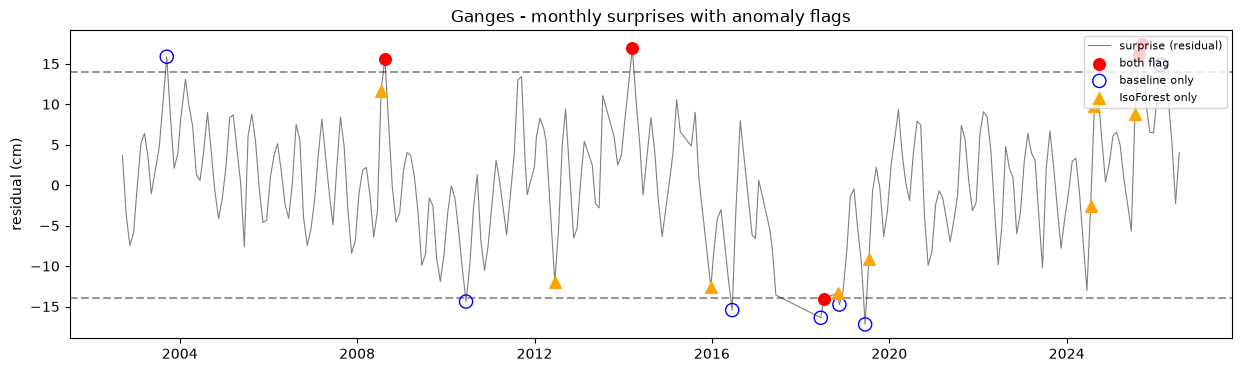

In [46]:
import matplotlib.pyplot as plt

r = resid.loc[feat.index]
bl = baseline_flag.loc[feat.index]
io = iso_flag

fig, ax = plt.subplots(figsize=(15,4))
ax.plot(r.index, r.values, color="grey", lw=0.8, label="surprise (residual)")
ax.axhline(2*sigma, ls="--", color="black", alpha=0.4)
ax.axhline(-2*sigma, ls ="--", color="black", alpha=0.4)

both = bl & io #both flag = both methods called it an anomaly
bonly = bl & ~io   #baseline only = the simple 2sigma rule flagged it, but the ML (IsoForest didn't)
ionly = io & ~bl #IsoForest only = the ML flagged it, but the simple rule didnt
ax.scatter(r.index[both], r.values[both], color="red", s=70, zorder=5, label="both flag")
ax.scatter(r.index[bonly], r.values[bonly], facecolors="none", edgecolors="blue", s=90, zorder=5, label="baseline only")
ax.scatter(r.index[ionly], r.values[ionly], color="orange", marker="^", s=70, zorder=5, label="IsoForest only")

ax.set_title("Ganges - monthly surprises with anomaly flags")
ax.set_ylabel("residual (cm)")
ax.legend(loc="upper right", fontsize=8)
plt.show()

# Residual = Actual - Predicted; Positive = more water than expected that month; negative = less water than expected

In [47]:
feat.loc[iso_flag & ~baseline_flag]

,resid,roll_sd,lag1,change
time,,,,
2008-07-16 12:00:00,11.613789,8.905351,-3.233672,14.847461
2012-06-16 00:00:00,-11.988462,8.212696,5.535897,-17.524358
2015-12-23 12:00:00,-12.630917,8.159475,1.033374,-13.664291
2018-10-31 12:00:00,-13.311101,1.223630,-14.057987,0.746887
2019-07-16 12:00:00,-9.179476,6.954682,-17.205216,8.025741
2024-07-16 12:00:00,-2.616549,9.444182,-13.021059,10.404510
2024-08-16 12:00:00,9.772914,9.756688,-2.616549,12.389463
2025-07-16 12:00:00,8.797100,9.725612,-5.671610,14.468710


In [ ]:
#Plant fake anamolies into clean data, then run both detectors on it head to head
#Determine how many false alarms each raised

import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

def make_features(r):
    s=pd.Series(r)
    return pd.DataFrame({"resid": s, "roll_sd": s.rolling(6,center=True).std(),
                         "lag1": s.shift(1), "change": s.diff()})

def detect(r, contamination, seed):
    f = make_features(r)
    valid = f.dropna().index
    X= StandardScaler().fit_transform(f.loc[valid])
    iso = IsolationForest(contamination=contamination, random_state=seed).fit_predict(X)
    iso_flag = np.zeros(len(r), bool)
    iso_flag[valid] = (iso == -1)
    base_flag = np.abs(r) > 2*np.nanstd(r)
    return iso_flag, base_flag

rng = np.random.default_rng(0)
n = len(t)
n_spikes = 8 
n_trials = 200
cont = n_spikes / n
IR, BR, IFp, BFp = [], [], [], []
for _ in range(n_trials):
    bg = ar1_noise(n, phi=0.5, sd=3.0, rng=rng)
    truth = np.zeros(n, bool)
    pos = rng.choice(np.arange(6,n-6), n_spikes, replace=False)
    bg[pos] += rng.choice([-1,1], n_spikes) * rng.uniform(8, 18, n_spikes)  # planted anomalies, varied size
    truth[pos] = True
    iso_flag, base_flag = detect(bg, cont, int(rng.integers(1e6)))
    IR.append(iso_flag[truth].sum()/n_spikes);  BR.append(base_flag[truth].sum()/n_spikes)
    IFp.append(iso_flag[~truth].sum());         BFp.append(base_flag[~truth].sum())

print(f"IsoForest — caught {100*np.mean(IR):.0f}% of planted, {np.mean(IFp):.1f} false flags/run")
print(f"Baseline  — caught {100*np.mean(BR):.0f}% of planted, {np.mean(BFp):.1f} false flags/run")

IsoForest — caught 49% of planted, 4.1 false flags/run
Baseline  — caught 84% of planted, 4.2 false flags/run


In [ ]:
# Add Median Absolute Deviation to the anomaly benchmark
# the 2sigma rule uses the mean and std, which outlier can distort
# MAD uses the media for both the center and the spread, so a few big anomalies can't inflate the threshold

def detect(r, contamination, seed):
    f = make_features(r)
    valid = f.dropna().index
    X = StandardScaler().fit_transform(f.loc[valid])
    iso = IsolationForest(contamination=contamination, random_state=seed).fit_predict(X)
    iso_flag = np.zeros(len(r), bool)
    iso_flag[valid] = (iso == -1)
    base_flag = np.abs(r) > 2*np.nanstd(r)
    med = np.median(r)
    mad = np.median(np.abs(r-med))
    mad_flag = np.abs(0.6745*(r-med)/mad) > 3.5   # robust threshold
    
    return iso_flag, base_flag, mad_flag

rng = np.random.default_rng(0)
n = len(t) 
n_spikes = 8 
n_trials = 200
cont = n_spikes/n

IR = BR = MR = 0.0
IFp = BFp = MFp = 0.0

for _ in range(n_trials):
    bg = ar1_noise(n, phi=0.5, sd=3.0, rng=rng)
    truth = np.zeros(n, bool)
    pos = rng.choice(np.arange(6, n-6), n_spikes, replace=False)
    bg[pos] += rng.choice([-1,1], n_spikes) * rng.uniform(8, 18, n_spikes)
    truth[pos] = True
    i_f, b_f, m_f = detect(bg, cont, int(rng.integers(1e6)))
    IR+=i_f[truth].mean(); BR+=b_f[truth].mean(); MR+=m_f[truth].mean()
    IFp+=i_f[~truth].sum(); BFp+=b_f[~truth].sum(); MFp+=m_f[~truth].sum()

k=n_trials

print(f"IsoForest — {100*IR/k:.0f}% caught, {IFp/k:.1f} false/run")
print(f"2-sigma   — {100*BR/k:.0f}% caught, {BFp/k:.1f} false/run")
print(f"MAD       — {100*MR/k:.0f}% caught, {MFp/k:.1f} false/run")

#Output : we observed a precision-recall trade-off here
# 2sigma = high recall, low precision. Use it when missing a drought is the expensive mistake. We can catch 84%, but we'll also raise 4 false alarms each run
# MAD = high precision, low recall. The 0.1 false/run is excellent. When MAD flags a month, we can basically trust it's real. The trade-off is we can miss the subtler ones, use it when false alarm is the expensive mistake
# IF = loses on both axes for big spikes. But keep it for its one speciality : which is contextual swings, which this test didnt contain.

#MAD wins on precision : its threshold is built from the median, so the big anomalies cant inflate it. This is the robustness that fix 2sigma masking weakness

IsoForest — 49% caught, 4.1 false/run
2-sigma   — 84% caught, 4.2 false/run
MAD       — 53% caught, 0.1 false/run


In [ ]:
# Multiple-testing correction across 8 basins.  (FDR)
# We ran 8 trend tests, testing many at once inflates the chance one significant is a fluke.
# Benjamini Hochberg adjusts for this, by testing if they are truly statistically significant

from statsmodels.stats.multitest import multipletests

results["p_corrected"] = results["p_corrected"].astype(float)   # it was saved as text
reject, p_fdr, _, _ = multipletests(results["p_corrected"].values, alpha=0.05, method="fdr_bh")
results["p_fdr"] = p_fdr
results["significant_fdr"] = reject

results[["Basin", "slope_cm_yr", "p_corrected", "p_fdr", "significant_fdr"]]

# The output matches
# Significant even after Benjamini-Hochberg correction across all eight basins

,Basin,slope_cm_yr,p_corrected,p_fdr,significant_fdr
0,Ganges (N India),-1.072,3.600000e-11,2.880000e-10,True
1,North China Plain,-0.893,6.200000e-03,1.240000e-02,True
2,California C. Valley,-0.932,3.500000e-07,1.400000e-06,True
3,Amazon (control),0.229,1.800000e-01,2.057143e-01,False
4,Zambezi / Okavango (S Africa),0.065,8.600000e-01,8.600000e-01,False
5,Great Lakes (N America),0.326,1.100000e-01,1.466667e-01,False
6,NW Australia,0.215,8.700000e-02,1.392000e-01,False
7,East Africa Lakes,1.634,1.100000e-05,2.933333e-05,True


In [ ]:
#Block-size robutness check 
#Confirm our bootstrap CI doesnt depend on the block length we picked

for b in [12,24,36]:
    lo, hi = bootstrap_ci(deseasonalised, t, block=b)
    print (f"block={b}: CI [{lo:.2f}, {hi:.2f}]")

#Output are all coherent

block=12: CI [-1.29, -0.85]
block=24: CI [-1.30, -0.83]
block=36: CI [-1.29, -0.83]


In [63]:
# Prepare csv files for our interactive Streamlit files

from pathlib import Path
out = Path("../outputs"); (out/"basins").mkdir(parents=True, exist_ok=True)

def freeze_basin(name, lat0, lat1, lon0, lon1):
    s = extract_basin(da, lat0, lat1, lon0, lon1)
    t, y = deseasonalise(s)
    slope, intercept, *_ = theilslopes(y, t)
    trend_line = intercept + slope*t
    resid = y - trend_line
    sigma = np.std(resid); med = np.median(resid); mad = np.median(np.abs(resid-med))
    df = pd.DataFrame({
        "raw": s.values, "deseasonalized": y, "trend_line": trend_line, "residual": resid,
        "flag_2sigma": np.abs(resid) > 2*sigma,
        "flag_mad": np.abs(0.6745*(resid-med)/mad) > 3.5,
    }, index=s.index)
    f = make_features(resid).reset_index(drop=True)      # Isolation Forest flags
    if_flag = np.zeros(len(resid), bool); valid = f.dropna().index.values
    Xs = StandardScaler().fit_transform(f.loc[valid])
    if_flag[valid] = IsolationForest(contamination=0.05, random_state=0).fit_predict(Xs) == -1
    df["flag_if"] = if_flag
    df.index.name = "date"
    slug = name.split("(")[0].strip().replace(" ","_").replace("/","_")
    df.to_csv(out/"basins"/f"{slug}.csv")
    return slug

# freeze every basin + build a summary table with map coordinates
meta = []
for (name, lat0, lat1, lon0, lon1) in basins:
    slug = freeze_basin(name, lat0, lat1, lon0, lon1)
    lon_c = (((lon0+lon1)/2 + 180) % 360) - 180          # 0-360 -> -180..180 for the map
    meta.append({"Basin": name, "slug": slug, "lat": (lat0+lat1)/2, "lon": lon_c})

summary = results.merge(pd.DataFrame(meta), on="Basin", how="left")
summary.to_csv(out/"summary.csv", index=False)
print("Frozen", len(meta), "basins ->", (out/"basins").resolve())
summary[["Basin","slug","slope_cm_yr","trend","CI_low","CI_high","lat","lon"]]

/var/folders/tb/3_7s5sgs5lbd692jwwyps_r80000gn/T/ipykernel_38614/3742232011.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = sm.OLS(s.values, X).fit()
/var/folders/tb/3_7s5sgs5lbd692jwwyps_r80000gn/T/ipykernel_38614/3742232011.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = sm.OLS(s.values, X).fit()
/var/folders/tb/3_7s5sgs5lbd692jwwyps_r80000gn/T/ipykernel_38614/3742232011.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = sm.OLS(s.values, X).fit()
/var/folders/tb/3_7s5sgs5lbd692jwwyps_r80000gn/T/ipykernel_38614/3742232011.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = sm.OLS(s.values, X).fit()
/var/folders/tb/3_7s5sgs5lbd692jwwyps_r80000gn/T/ipykernel_38614/3742232011.py:21: SingularMatrixWar

Frozen 8 basins -> /Users/heeowen/Projects/hydrogeopulse/outputs/basins


/var/folders/tb/3_7s5sgs5lbd692jwwyps_r80000gn/T/ipykernel_38614/3742232011.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = sm.OLS(s.values, X).fit()


,Basin,slug,slope_cm_yr,trend,CI_low,CI_high,lat,lon
0,Ganges (N India),Ganges,-1.072,decreasing,-1.31,-0.82,26.0,81.0
1,North China Plain,North_China_Plain,-0.893,decreasing,-1.35,-0.46,37.0,116.5
2,California C. Valley,California_C._Valley,-0.932,decreasing,-1.37,-0.54,37.5,-120.0
3,Amazon (control),Amazon,0.229,no trend,-0.11,0.61,-4.0,-60.0
4,Zambezi / Okavango (S Africa),Zambezi___Okavango,0.065,no trend,-0.50,0.67,-15.0,25.0
5,Great Lakes (N America),Great_Lakes,0.326,no trend,-0.15,0.81,45.0,-88.0
6,NW Australia,NW_Australia,0.215,no trend,-0.01,0.42,-18.0,126.0
7,East Africa Lakes,East_Africa_Lakes,1.634,increasing,1.24,1.97,0.0,35.0


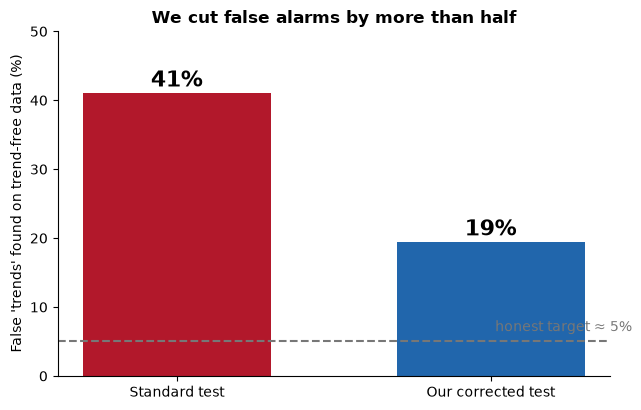

In [69]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6.5, 4.2))
bars = ax.bar(["Standard test", "Our corrected test"], [41.0, 19.4],
              color=["#b2182b", "#2166ac"], width=0.6)
ax.axhline(5, ls="--", color="#777")
ax.text(1.45, 6.5, "honest target ≈ 5%", color="#777", fontsize=10, ha="right")
for b, v in zip(bars, [41.0, 19.4]):
    ax.text(b.get_x() + b.get_width()/2, v + 1, f"{v:.0f}%", ha="center",
            fontsize=16, fontweight="bold")
ax.set_ylabel("False 'trends' found on trend-free data (%)")
ax.set_title("We cut false alarms by more than half", fontweight="bold")
ax.set_ylim(0, 50)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../outputs/false_alarm.png", dpi=200, bbox_inches="tight")
plt.show()